# Hotel Booking Demand - Multiclass Market Segment Classification

## 1. Business Problem & Project Overview
This project develops a robust, end-to-end Machine Learning pipeline to predict the `market_segment` of hotel bookings based on guest demographics, booking details and stay characteristics.

**Objective:** Build a scalable, production-ready multiclass classification system that identifies the segment of a booking **at the moment it is made**, to support revenue management, auditing of segment labels and marketing efforts.

**Key Workflow Steps:**
1. Data Acquisition, Cleaning & Feature Scoping
2. Exploratory Data Analysis (EDA)
3. Feature Engineering & Preprocessing Pipelines
4. Model Benchmarking (Validation Set Evaluation)
5. Automatic Hyperparameter Tuning using Optuna
6. Final Model Evaluation & Diagnostics

## 2. Environment Setup & Imports

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split

# imbalanced-learn Pipeline: applies resampling only during fit, never during predict
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import f1_score, confusion_matrix, classification_report, roc_curve, auc

import optuna

RANDOM_STATE = 42
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid", palette="muted")

## 3. Data Loading, Cleaning & Feature Scoping
The model predicts the segment **at booking time**, so the feature set is scoped to what is actually known at that moment:

* **Post-booking attributes are excluded** (`is_canceled`, `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`): they are only known after the booking is made, so using them would leak future information.
* **Channel identifiers are excluded** (`distribution_channel`, `agent`, `company`): they encode the segment almost one-to-one, so the model would read the answer instead of learning booking behavior.

Loading and cleaning are wrapped in a function to ensure reproducibility.

In [2]:
# The notebook may be run from the project root or from notebooks/
CANDIDATE_PATHS = [os.path.join("..", "data", "hotel_bookings.csv"), os.path.join("data", "hotel_bookings.csv")]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
TARGET = 'market_segment'

# Known only after the booking is made: using them would leak the future into training.
POST_BOOKING_COLS = ['is_canceled', 'reservation_status', 'reservation_status_date',
                     'assigned_room_type', 'booking_changes']
# Channel identifiers that are near-deterministic proxies of the market segment.
CHANNEL_ID_COLS = ['distribution_channel', 'agent', 'company']

def load_and_clean_data(filepath: str) -> pd.DataFrame:
    """Load the raw CSV, drop duplicates and keep only booking-time features."""
    if filepath is None:
        raise FileNotFoundError("hotel_bookings.csv not found. Place it in the project's data/ folder.")
    df = pd.read_csv(filepath)

    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

    initial_rows = df.shape[0]
    df = df.drop_duplicates()
    print(f"Removed {initial_rows - df.shape[0]} duplicate rows.")

    df = df.drop(columns=POST_BOOKING_COLS + CHANNEL_ID_COLS)

    # Drop rows with missing target and classes too rare for a stratified split
    df = df.dropna(subset=[TARGET])
    target_counts = df[TARGET].value_counts()
    df = df[df[TARGET].isin(target_counts[target_counts >= 10].index)]

    # Convert month names to integers for cyclical encoding
    month_map = {
        'January': 1, 'February': 2, 'March': 3, 'April': 4,
        'May': 5, 'June': 6, 'July': 7, 'August': 8,
        'September': 9, 'October': 10, 'November': 11, 'December': 12
    }
    df['month'] = df['arrival_date_month'].map(month_map)
    df = df.drop(columns=['arrival_date_month'])

    print(f"Data loaded successfully. Final shape: {df.shape}")
    return df

df = load_and_clean_data(DATA_PATH)
display(df.head())

Removed 31994 duplicate rows.
Data loaded successfully. Final shape: (87394, 24)


,hotel,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,month
0,Resort Hotel,342,2015,27,1,0,0,2,0.0,0,BB,PRT,Direct,0,0,0,C,No Deposit,0,Transient,0.0,0,0,7
1,Resort Hotel,737,2015,27,1,0,0,2,0.0,0,BB,PRT,Direct,0,0,0,C,No Deposit,0,Transient,0.0,0,0,7
2,Resort Hotel,7,2015,27,1,0,1,1,0.0,0,BB,GBR,Direct,0,0,0,A,No Deposit,0,Transient,75.0,0,0,7
3,Resort Hotel,13,2015,27,1,0,1,1,0.0,0,BB,GBR,Corporate,0,0,0,A,No Deposit,0,Transient,75.0,0,0,7
4,Resort Hotel,14,2015,27,1,0,2,2,0.0,0,BB,GBR,Online TA,0,0,0,A,No Deposit,0,Transient,98.0,0,1,7


## 4. Exploratory Data Analysis (EDA)
Understanding the distribution of the target variable and the relationships among key features is critical for model formulation.

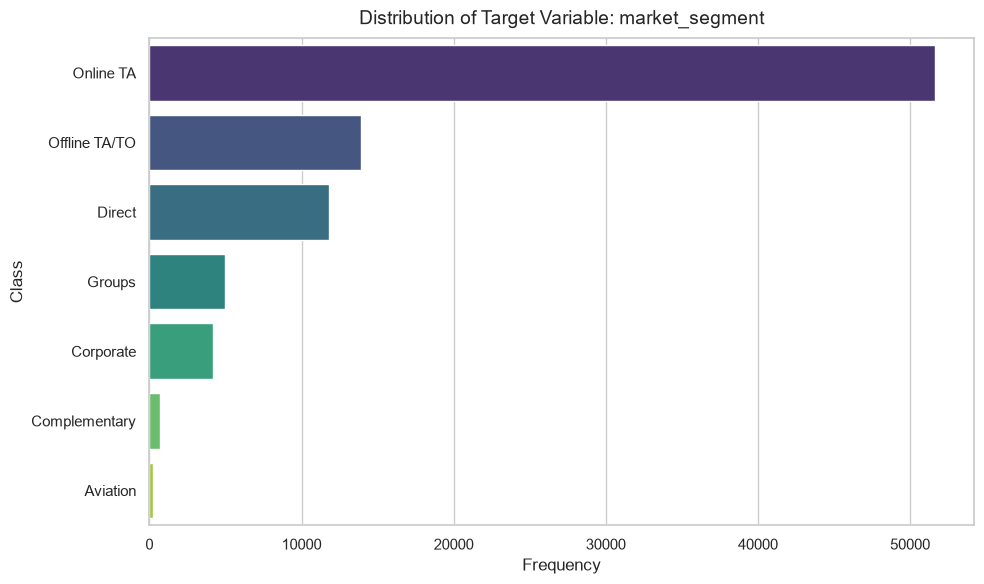

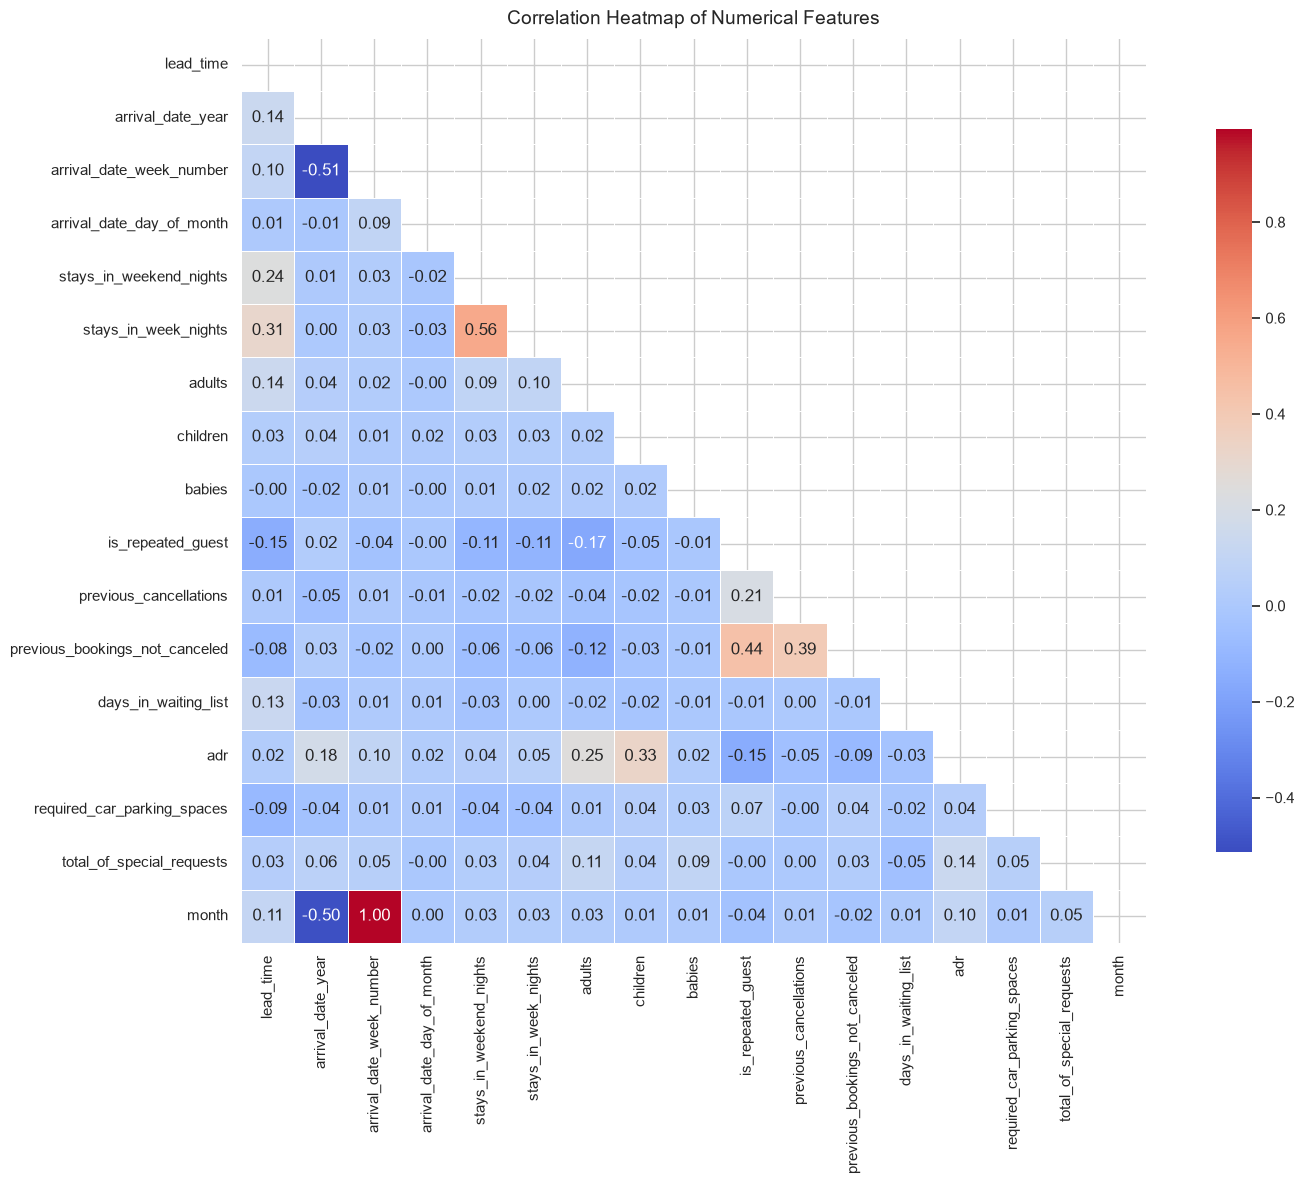

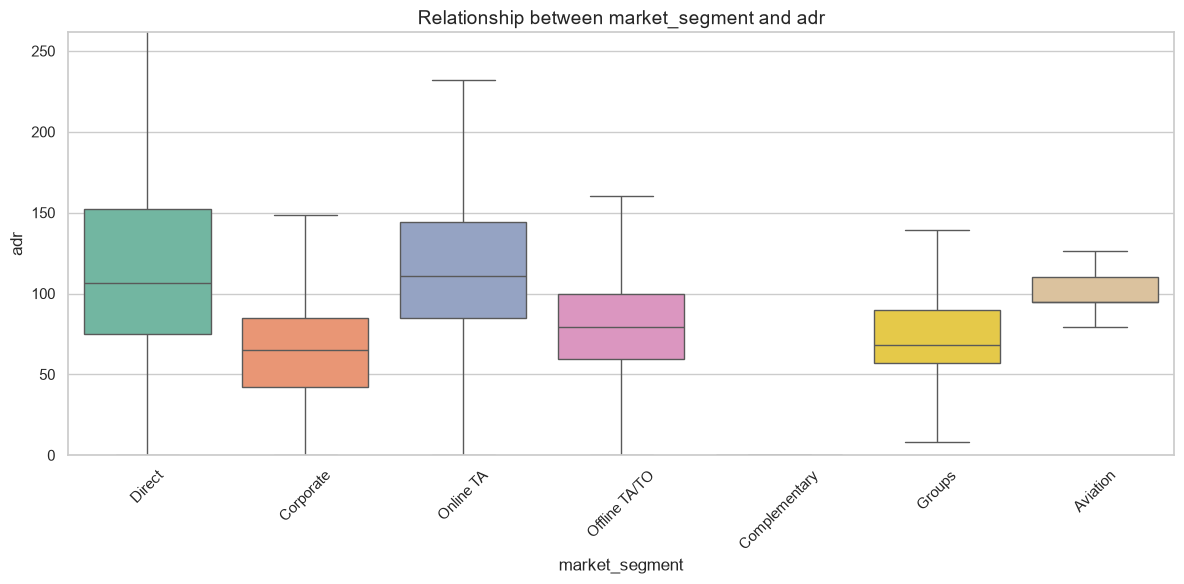

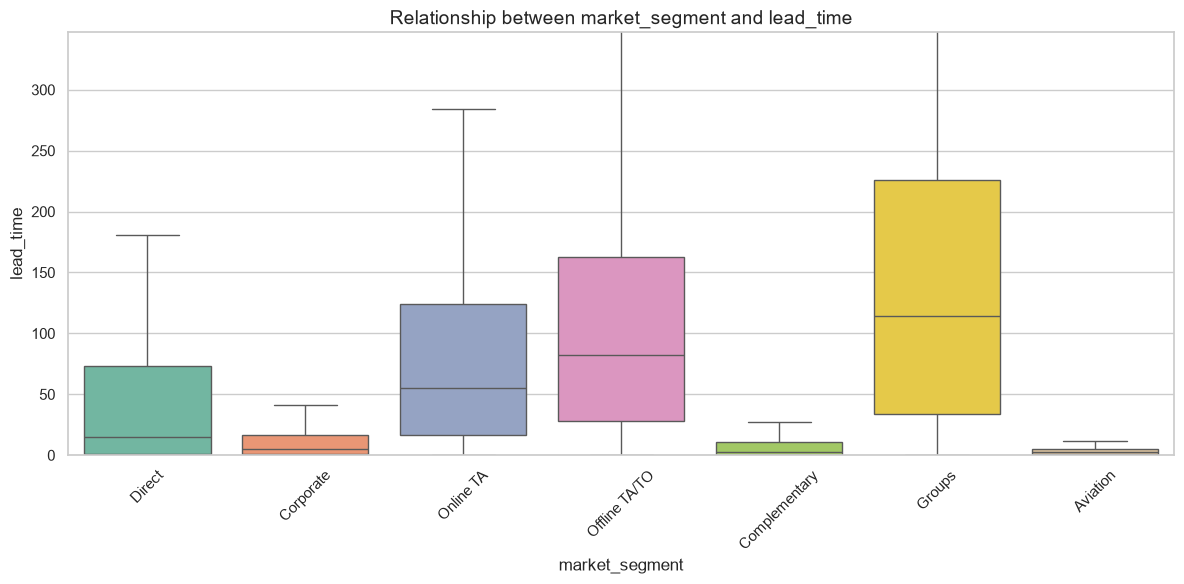

In [3]:
def plot_target_distribution(data: pd.DataFrame, target_col: str):
    plt.figure(figsize=(10, 6))
    order = data[target_col].value_counts().index
    sns.countplot(data=data, y=target_col, order=order, palette="viridis")
    plt.title(f"Distribution of Target Variable: {target_col}", fontsize=14, pad=10)
    plt.xlabel("Frequency", fontsize=12)
    plt.ylabel("Class", fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_correlation_matrix(data: pd.DataFrame):
    corr = data.select_dtypes(include=[np.number]).corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    plt.figure(figsize=(16, 12))
    sns.heatmap(corr, annot=True, fmt=".2f", mask=mask, cmap="coolwarm",
                square=True, linewidths=.5, cbar_kws={"shrink": .8})
    plt.title("Correlation Heatmap of Numerical Features", fontsize=14, pad=10)
    plt.tight_layout()
    plt.show()

def plot_bivariate_analysis(data: pd.DataFrame, num_col: str, cat_col: str, upper_quantile=0.99):
    plt.figure(figsize=(12, 6))
    # Fliers hidden and the axis capped at a high quantile, so a handful of extreme
    # values (adr, lead_time) don't squash every box against the baseline.
    sns.boxplot(data=data, x=cat_col, y=num_col, palette="Set2", showfliers=False)
    plt.ylim(0, data[num_col].quantile(upper_quantile))
    plt.title(f"Relationship between {cat_col} and {num_col}", fontsize=14)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_target_distribution(df, TARGET)
plot_correlation_matrix(df)
plot_bivariate_analysis(df, 'adr', TARGET)
plot_bivariate_analysis(df, 'lead_time', TARGET)

## 5. Train-Validation-Test Split
We use a stratified split to isolate three explicit datasets:
* **Train:** Used to fit models.
* **Validation:** Used to benchmark models and tune hyperparameters without data leakage.
* **Test:** Strictly reserved for final model diagnostics.

In [4]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Encode the target variable (required by XGBoost and LightGBM)
label_enc = LabelEncoder()
y_encoded = label_enc.fit_transform(y)

# Two stratified splits: 64% train, 16% validation (model selection and tuning),
# 20% test (touched once, at the very end).
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=RANDOM_STATE, stratify=y_encoded)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=RANDOM_STATE, stratify=y_temp)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (55932, 23)
Validation set shape: (13983, 23)
Testing set shape: (17479, 23)


## 6. Feature Engineering & Custom Transformers
Custom Scikit-Learn transformers guarantee that every feature engineering step is applied through pipelines, strictly preventing data leakage across splits.

In [5]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Stateless domain features: stay length, party composition and cyclical seasonality."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()

        X_out['total_nights'] = X_out['stays_in_weekend_nights'] + X_out['stays_in_week_nights']
        kids = X_out['children'].fillna(0) + X_out['babies']
        X_out['total_guests'] = X_out['adults'] + kids
        X_out['has_kids'] = (kids > 0).astype(int)

        # Seasonality: cyclical encoding so that December sits next to January
        X_out['month_sin'] = np.sin(2 * np.pi * X_out['month'] / 12)
        X_out['month_cos'] = np.cos(2 * np.pi * X_out['month'] / 12)
        X_out['week_sin'] = np.sin(2 * np.pi * X_out['arrival_date_week_number'] / 53)
        X_out['week_cos'] = np.cos(2 * np.pi * X_out['arrival_date_week_number'] / 53)

        return X_out.drop(columns=['month', 'arrival_date_week_number'])

class IQRTransformer(BaseEstimator, TransformerMixin):
    """Clip each column to [Q1 - k*IQR, Q3 + k*IQR], with the bounds learned in fit."""

    def __init__(self, iqr_factor=1.5):
        self.iqr_factor = iqr_factor

    def fit(self, X, y=None):
        X_array = np.asarray(X, dtype=float)
        q1 = np.nanpercentile(X_array, 25, axis=0)
        q3 = np.nanpercentile(X_array, 75, axis=0)
        iqr = q3 - q1
        # Columns with zero IQR (binary flags, sparse counts) are left untouched:
        # clipping them would collapse every non-zero value into a constant.
        self.lower_ = np.where(iqr > 0, q1 - self.iqr_factor * iqr, -np.inf)
        self.upper_ = np.where(iqr > 0, q3 + self.iqr_factor * iqr, np.inf)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

class RareCategoryEncoder(BaseEstimator, TransformerMixin):
    """Map categories rarer than `threshold` (share of training rows) to 'Other'.

    Keeps the one-hot matrix narrow instead of one near-empty column per rare level.
    """

    def __init__(self, threshold=0.01):
        self.threshold = threshold

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.columns_ = X_df.columns
        self.freqs_ = {col: X_df[col].value_counts(normalize=True) for col in self.columns_}
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X, columns=self.columns_)
        for col in self.columns_:
            rare = self.freqs_[col][self.freqs_[col] < self.threshold].index
            X_df[col] = X_df[col].replace(rare, "Other")
        return X_df.values

## 7. Defining Preprocessing & Resampling
Numerical and categorical features follow separate pipelines. For class imbalance we use **moderate SMOTE oversampling** inside the imbalanced-learn pipeline: every minority class is raised to at least 15% of the majority class. Full balancing would multiply the smallest class by more than 200 with synthetic points, so a moderate target keeps the training data closer to reality while still giving the small segments enough weight.

In [6]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('outliers', IQRTransformer(iqr_factor=1.5)),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('rare', RareCategoryEncoder(threshold=0.01)),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Columns are routed by dtype, so the engineered features need no manual listing.
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, make_column_selector(dtype_include=np.number)),
    ('cat', cat_pipeline, make_column_selector(dtype_exclude=np.number))
])

data_pipeline = Pipeline([
    ('feat_eng', FeatureEngineer()),
    ('preprocess', preprocessor)
])

def moderate_oversampling(y, min_share=0.15):
    """SMOTE targets: lift each minority class to `min_share` of the majority class.

    Full balancing would create tens of thousands of synthetic rows interpolated
    from the few real ones of the smallest segments.
    """
    counts = pd.Series(y).value_counts()
    target = int(counts.max() * min_share)
    return {cls: target for cls, n in counts.items() if n < target}

def build_pipeline(model):
    """Preprocessing -> SMOTE -> classifier. SMOTE runs on fit only, never on predict."""
    return Pipeline(list(data_pipeline.steps) + [
        ('resample', SMOTE(sampling_strategy=moderate_oversampling, random_state=RANDOM_STATE)),
        ('classifier', model)
    ])

## 8. Model Benchmarking (Validation Set Evaluation)
Models are fit exclusively on `X_train` and scored on `X_val`. The selection metric is the **macro F1-Score**: it gives every segment the same weight, so a model cannot win by excelling only on the majority class. The weighted F1-Score is reported alongside it.

Evaluating Logistic Regression...


Evaluating Random Forest...


Evaluating Gradient Boosting...


Evaluating XGBoost...


Evaluating LightGBM...


,Model,Validation_F1_Macro,Validation_F1_Weighted
0,Random Forest,0.753956,0.805322
1,XGBoost,0.747428,0.803334
2,LightGBM,0.743835,0.795415
3,Gradient Boosting,0.647814,0.735112
4,Logistic Regression,0.504840,0.661433


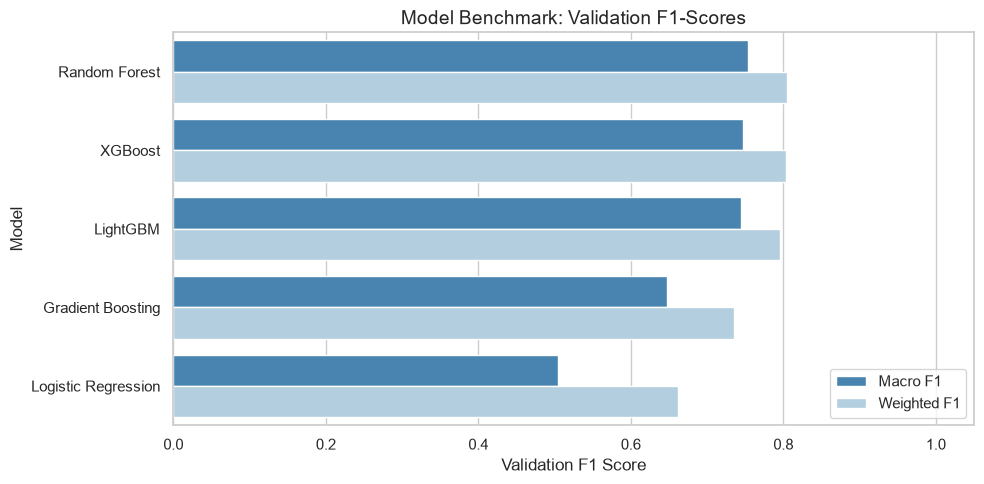

In [7]:
# Single source of truth for every candidate: class + fixed base parameters.
# The benchmark and the tuning step both build models from here.
MODEL_REGISTRY = {
    'Logistic Regression': (LogisticRegression, {'max_iter': 2000, 'random_state': RANDOM_STATE}),
    'Random Forest': (RandomForestClassifier, {'n_estimators': 300, 'n_jobs': -1, 'random_state': RANDOM_STATE}),
    'Gradient Boosting': (GradientBoostingClassifier, {'random_state': RANDOM_STATE}),
    'XGBoost': (XGBClassifier, {'eval_metric': 'mlogloss', 'tree_method': 'hist', 'n_jobs': -1,
                                'random_state': RANDOM_STATE}),
    'LightGBM': (LGBMClassifier, {'n_jobs': -1, 'random_state': RANDOM_STATE, 'verbose': -1})
}

def get_model_instance(model_name, params=None):
    """Build a registry model; `params` (e.g. tuned values) override the base ones."""
    model_class, base_params = MODEL_REGISTRY[model_name]
    return model_class(**{**base_params, **(params or {})})

benchmark_models = {name: get_model_instance(name) for name in MODEL_REGISTRY}

def run_benchmark(models_dict, X_train_split, y_train_split, X_val_split, y_val_split):
    """Fit every model on train and rank them by validation macro F1."""
    results = []
    for name, model in models_dict.items():
        print(f"Evaluating {name}...")
        model_pipeline = build_pipeline(model)
        model_pipeline.fit(X_train_split, y_train_split)

        y_val_pred = model_pipeline.predict(X_val_split)
        results.append({
            'Model': name,
            'Validation_F1_Macro': f1_score(y_val_split, y_val_pred, average='macro'),
            'Validation_F1_Weighted': f1_score(y_val_split, y_val_pred, average='weighted')
        })
    return pd.DataFrame(results).sort_values(by='Validation_F1_Macro', ascending=False).reset_index(drop=True)

benchmark_results = run_benchmark(benchmark_models, X_train, y_train, X_val, y_val)
display(benchmark_results)

plot_df = benchmark_results.melt(id_vars='Model', var_name='Metric', value_name='Score')
plot_df['Metric'] = plot_df['Metric'].map({'Validation_F1_Macro': 'Macro F1', 'Validation_F1_Weighted': 'Weighted F1'})
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, x='Score', y='Model', hue='Metric', palette='Blues_r')
plt.title("Model Benchmark: Validation F1-Scores", fontsize=14)
plt.xlabel("Validation F1 Score")
plt.ylabel("Model")
plt.xlim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 9. Automatic Hyperparameter Tuning (Optuna)
The top-performing model from the benchmark is identified dynamically and tuned with Optuna. Each trial fits on `X_train` and is scored on `X_val` (macro F1), providing an objective optimization loop without data leakage. Tuned parameters are adopted only if they beat the benchmark configuration.

In [8]:
# The benchmark is sorted by validation macro F1, so the first row is the winner.
best_model_name = benchmark_results.iloc[0]['Model']
print(f"Best model automatically selected for tuning: {best_model_name}")

def get_optuna_params(trial, model_name):
    """Optuna search space for each registry model."""
    if model_name == 'Logistic Regression':
        return {'C': trial.suggest_float('C', 0.01, 10.0, log=True)}
    elif model_name == 'Random Forest':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 200, 800),
            'max_depth': trial.suggest_categorical('max_depth', [None, 15, 25, 40]),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 4),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.3, 0.5])
        }
    elif model_name == 'Gradient Boosting':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 8)
        }
    elif model_name == 'XGBoost':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 200, 1000),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0)
        }
    elif model_name == 'LightGBM':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 200, 1000),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 20, 150),
            'max_depth': trial.suggest_int('max_depth', 3, 12),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'subsample_freq': 1,
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0)
        }
    return {}

def objective(trial, model_name, X_train_split, y_train_split, X_val_split, y_val_split):
    """Validation macro F1 of one trial; the test set never takes part in tuning."""
    model_instance = get_model_instance(model_name, get_optuna_params(trial, model_name))
    full_pipeline = build_pipeline(model_instance)
    full_pipeline.fit(X_train_split, y_train_split)
    y_val_pred = full_pipeline.predict(X_val_split)
    return f1_score(y_val_split, y_val_pred, average='macro')

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))

N_TRIALS = 25
print(f"Starting Optuna tuning for {best_model_name} ({N_TRIALS} trials)...")
study.optimize(lambda trial: objective(trial, best_model_name, X_train, y_train, X_val, y_val),
               n_trials=N_TRIALS, show_progress_bar=False)

baseline_macro = benchmark_results.iloc[0]['Validation_F1_Macro']
print("Optimization Completed.")
print(f"Benchmark configuration Macro F1: {baseline_macro:.4f}")
print(f"Best Optuna trial Macro F1:       {study.best_value:.4f}")

# Tuned parameters are adopted only if they beat the benchmark configuration on validation
if study.best_value > baseline_macro:
    final_params = study.best_params
    print(f"Tuned parameters adopted: {final_params}")
else:
    final_params = {}
    print("No trial beat the benchmark configuration; keeping the base parameters.")

Best model automatically selected for tuning: Random Forest
Starting Optuna tuning for Random Forest (25 trials)...


Optimization Completed.
Benchmark configuration Macro F1: 0.7540
Best Optuna trial Macro F1:       0.7587
Tuned parameters adopted: {'n_estimators': 495, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.3}


## 10. Final Model Evaluation on the Unseen Test Set
With hyperparameters finalized on the validation set, the final model is retrained on Train + Validation to maximize learning before predicting on the unseen Test set.

In [9]:
final_model_instance = get_model_instance(best_model_name, final_params)
final_pipeline = build_pipeline(final_model_instance)

# Hyperparameters are frozen, so refit on train + validation before the one-off test run.
X_train_full = pd.concat([X_train, X_val])
y_train_full = np.concatenate([y_train, y_val])
final_pipeline.fit(X_train_full, y_train_full)

y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)

# Back to segment names for the report and the plots.
y_test_original = label_enc.inverse_transform(y_test)
y_pred_original = label_enc.inverse_transform(y_test_pred)

print(f"Test Macro F1:    {f1_score(y_test, y_test_pred, average='macro'):.4f}")
print(f"Test Weighted F1: {f1_score(y_test, y_test_pred, average='weighted'):.4f}")
print("\nClassification Report (Final Test Set):\n")
print(classification_report(y_test_original, y_pred_original))

Test Macro F1:    0.7688
Test Weighted F1: 0.8155

Classification Report (Final Test Set):

               precision    recall  f1-score   support

     Aviation       0.68      0.71      0.70        45
Complementary       0.80      0.90      0.85       140
    Corporate       0.75      0.76      0.75       842
       Direct       0.68      0.43      0.53      2361
       Groups       0.87      0.91      0.89       989
Offline TA/TO       0.85      0.72      0.78      2778
    Online TA       0.84      0.94      0.89     10324

     accuracy                           0.83     17479
    macro avg       0.78      0.77      0.77     17479
 weighted avg       0.82      0.83      0.82     17479



## 11. Advanced Visual Diagnostics
Confusion matrix and One-vs-Rest ROC curves on the unseen test set.

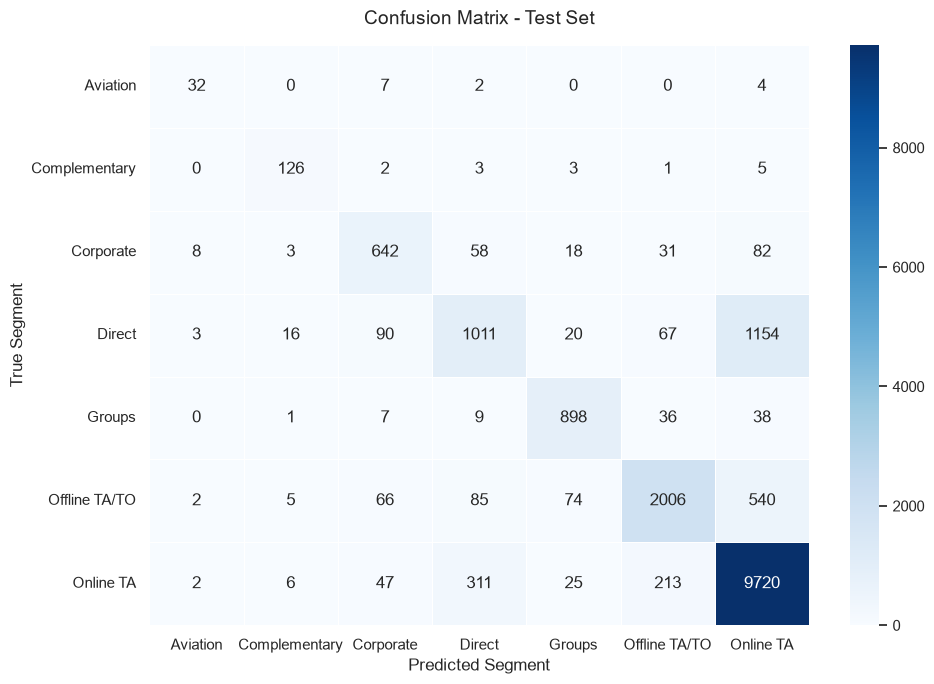

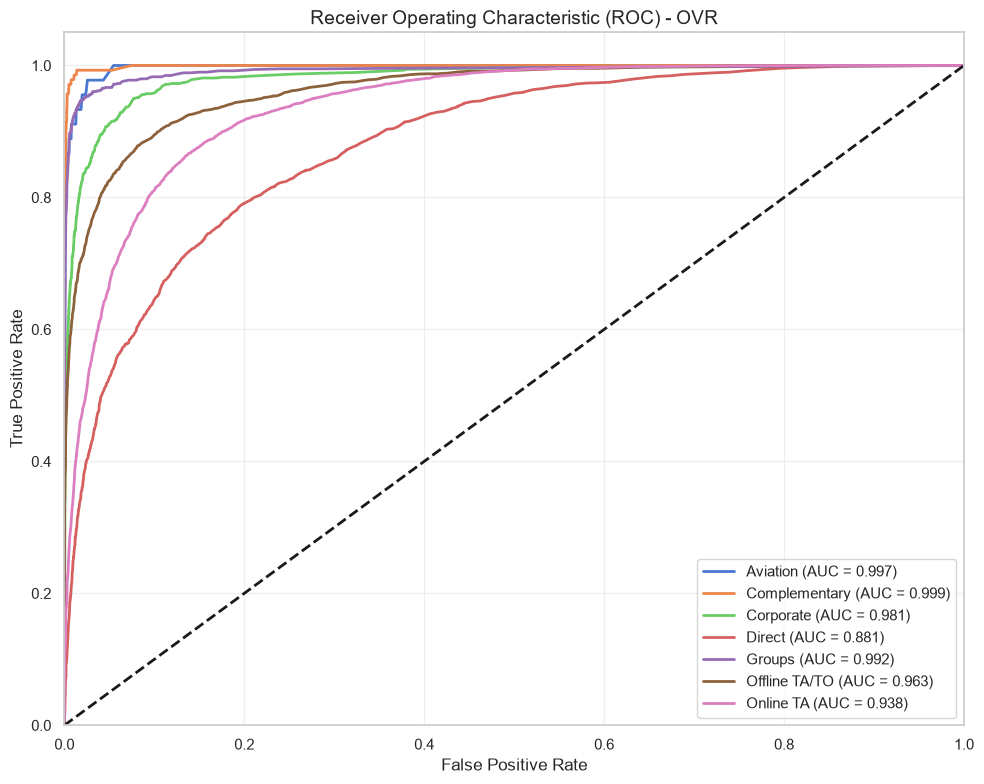

In [10]:
def plot_confusion_matrix_heatmap(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes, linewidths=0.5)
    plt.xlabel('Predicted Segment', fontsize=12)
    plt.ylabel('True Segment', fontsize=12)
    plt.title('Confusion Matrix - Test Set', fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()

def plot_multiclass_roc(y_true_enc, y_proba, classes):
    """One-vs-rest ROC curve and AUC for each class."""
    y_true_bin = label_binarize(y_true_enc, classes=np.arange(len(classes)))
    plt.figure(figsize=(10, 8))
    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba[:, i])
        plt.plot(fpr, tpr, lw=2, label=f'{cls} (AUC = {auc(fpr, tpr):.3f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('Receiver Operating Characteristic (ROC) - OVR', fontsize=14)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

target_classes = label_enc.classes_
plot_confusion_matrix_heatmap(y_test_original, y_pred_original, target_classes)
plot_multiclass_roc(y_test, y_test_proba, target_classes)